Cell 1: Imports & Setup

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# --- SETUP ---
# Add project root to path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
    
# PCA Configuration
N_COMPONENTS = 20
N_FACTORS_REMOVED = 10

DATA_PROCESSED = project_root / "data_processed"
plt.style.use('bmh')
print(f"Project Root: {project_root}")

Project Root: c:\Users\sanka\OneDrive\Documents\MMU\ML STATISTICAL ARBITRAGE


Data Loading Function:

In [2]:
def load_returns(market_prefix, cohort_type):
    """
    Load cleaned log-return matrix.

    Parameters
    ----------
    market_prefix : str
        nifty500 or sp500

    cohort_type : str
        long  -> 2007-2026
        broad -> 2015-2026
    """

    if cohort_type == "broad":
        filename = f"{market_prefix}_2015_returns.parquet"
        label = "Broad Market (2015-2026)"
    else:
        filename = f"{market_prefix}_returns.parquet"
        label = "Long History (2007-2026)"

    file_path = DATA_PROCESSED / filename

    if not file_path.exists():
        print(f"File not found: {filename}")
        return None, label

    returns = pd.read_parquet(file_path)

    # -------------------------
    # Keep stocks with >=90% data
    # -------------------------
    min_obs = int(0.90 * len(returns))

    returns = returns.dropna(axis=1, thresh=min_obs)

    print(
        f"Loaded {label}: "
        f"{returns.shape[0]} Days × "
        f"{returns.shape[1]} Stocks"
    )

    return returns, label

PCA & Plotting Function

In [3]:
# --- FUNCTION 2: RUN PCA & PLOT ---
def run_pca_analysis(market_name, market_prefix, cohort_type):
    # 1. Load Data
    returns_df, label = load_returns(market_prefix, cohort_type)
    if returns_df is None: return

   
    # Clean remaining missing values
    X = returns_df.dropna(axis=0)

    # Standardize Returns
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    # PCA
    pca = PCA(
        n_components=N_COMPONENTS,
        random_state=42)
    pca.fit(X_scaled)
    
    # 3. Get Variance Stats
    explained_var = pca.explained_variance_ratio_ * 100
    cumulative_var = np.cumsum(explained_var)
    
    # 4. PLOT 1: The "Elbow" Curve (Risk Explained)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    
    # Bar Chart
    ax1.bar(range(1, N_COMPONENTS + 1), explained_var, alpha=0.7, color='teal')
    ax1.set_title(f"{market_name} ({label})\nVariance Explained by Factor")
    ax1.set_ylabel("Variance (%)")
    ax1.text(1, explained_var[0], f"{explained_var[0]:.1f}%", ha='center', va='bottom')
    
    # Line Chart
    ax2.plot(range(1, N_COMPONENTS + 1), cumulative_var, marker='o', linestyle='--', color='darkred')
    ax2.set_title(f"{market_name}\nCumulative Risk Explained")
    ax2.axhline(y=50, color='grey', linestyle=':', label='50% Threshold')
    ax2.legend()
    plt.tight_layout()
    plt.show()

    # 5. PLOT 2: Market Factor Validation (The Fix!)
    # Get PC1 (The Market Factor)
    factors = pca.transform(X_scaled)
    pc1_array = factors[:, 0]
    
    # --- THE FIX: Attach Dates ---
    pc1_series = pd.Series(pc1_array,  index=X.index)
    
    # Market Average (Equal Weighted Index)
    market_index = X.mean(axis=1)
    
    # Check correlation to flip sign if needed
    corr = pc1_series.corr(market_index)
    if corr < 0:
        pc1_series = -pc1_series
        corr = -corr # Make positive for printing
        
    plt.figure(figsize=(12, 4))
    (np.cumsum(pc1_series)).plot(label='PCA Factor 1 (Hidden Force)', linewidth=1.5)
    (np.cumsum(market_index)).plot(label='Actual Market Average', linestyle='--', alpha=0.7)
    plt.title(f"{market_name} ({label}): Market Mode Validation")
    plt.legend()
    plt.show()
    
    print(f"✅ Correlation between PCA and Market: {corr:.4f}")
    print(f"PC1 Variance Explained: {explained_var[0]:.2f}%")
    print(f"Cumulative Variance ({N_COMPONENTS} PCs): {cumulative_var[-1]:.2f}%")
    print("-" * 80)

Main Execution

STARTING DUAL-COHORT ANALYSIS

Loaded Long History (2007-2026): 4691 Days × 278 Stocks


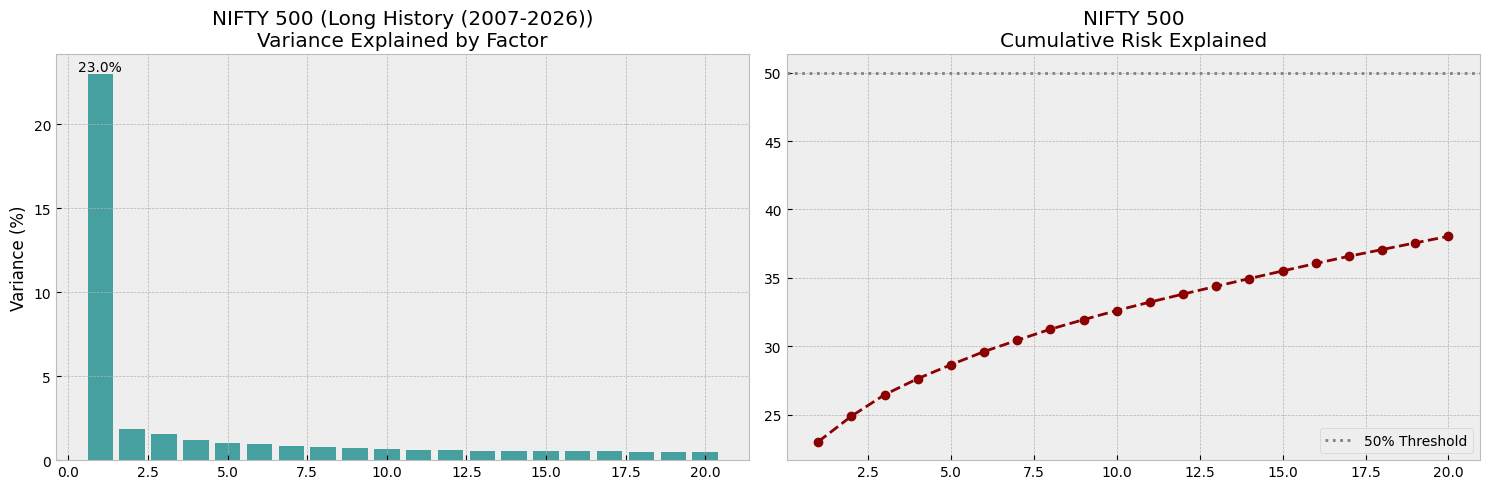

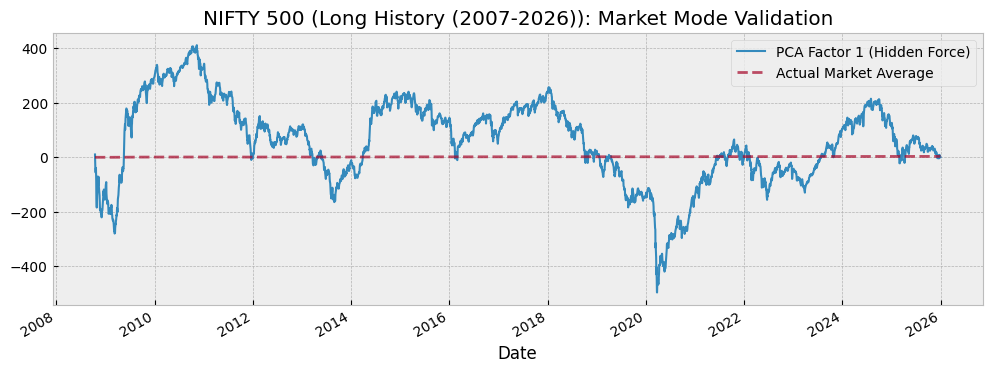

✅ Correlation between PCA and Market: 0.9984
PC1 Variance Explained: 23.02%
Cumulative Variance (20 PCs): 38.04%
--------------------------------------------------------------------------------
Loaded Broad Market (2015-2026): 2717 Days × 328 Stocks


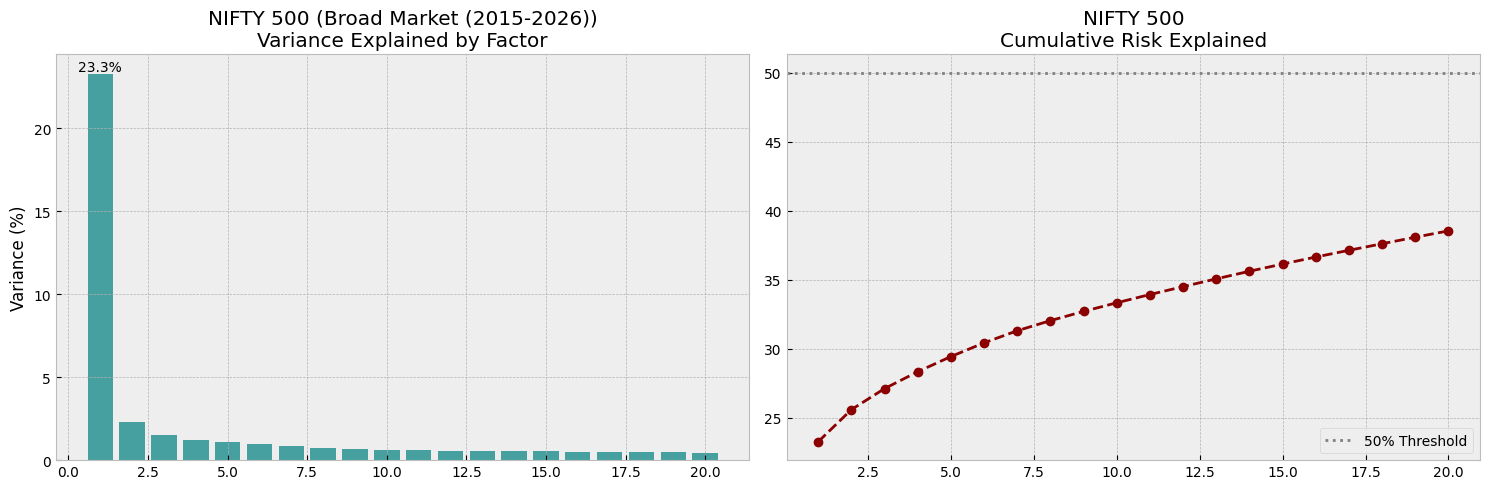

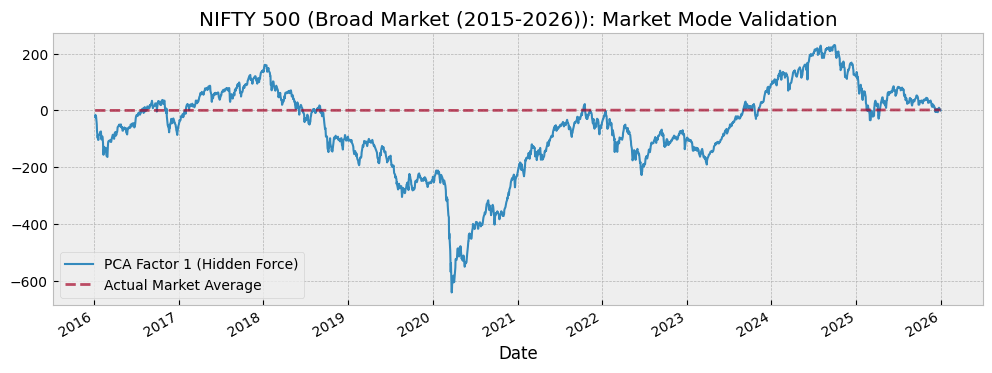

✅ Correlation between PCA and Market: 0.9976
PC1 Variance Explained: 23.28%
Cumulative Variance (20 PCs): 38.55%
--------------------------------------------------------------------------------
Loaded Long History (2007-2026): 4779 Days × 421 Stocks


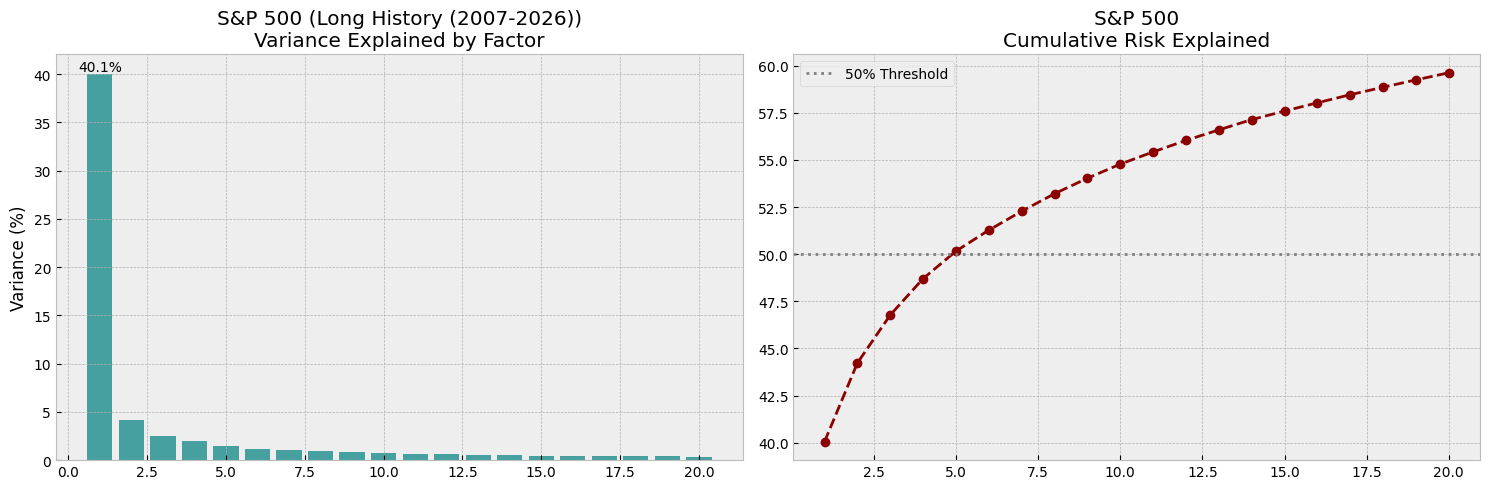

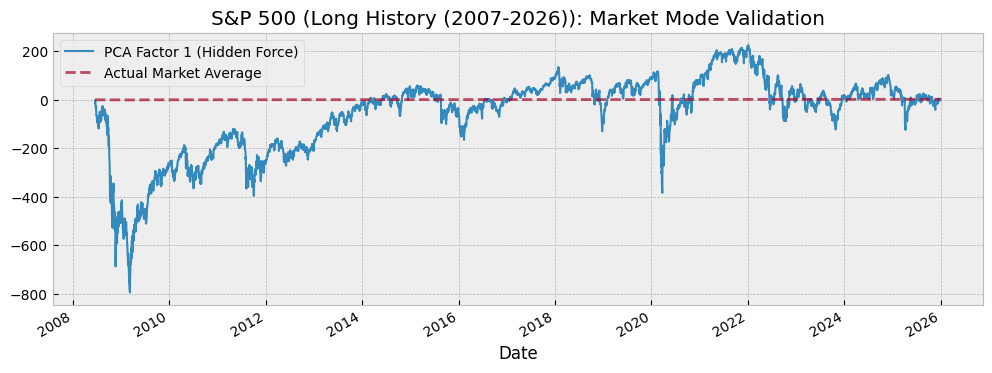

✅ Correlation between PCA and Market: 0.9984
PC1 Variance Explained: 40.05%
Cumulative Variance (20 PCs): 59.62%
--------------------------------------------------------------------------------
Loaded Broad Market (2015-2026): 2765 Days × 469 Stocks


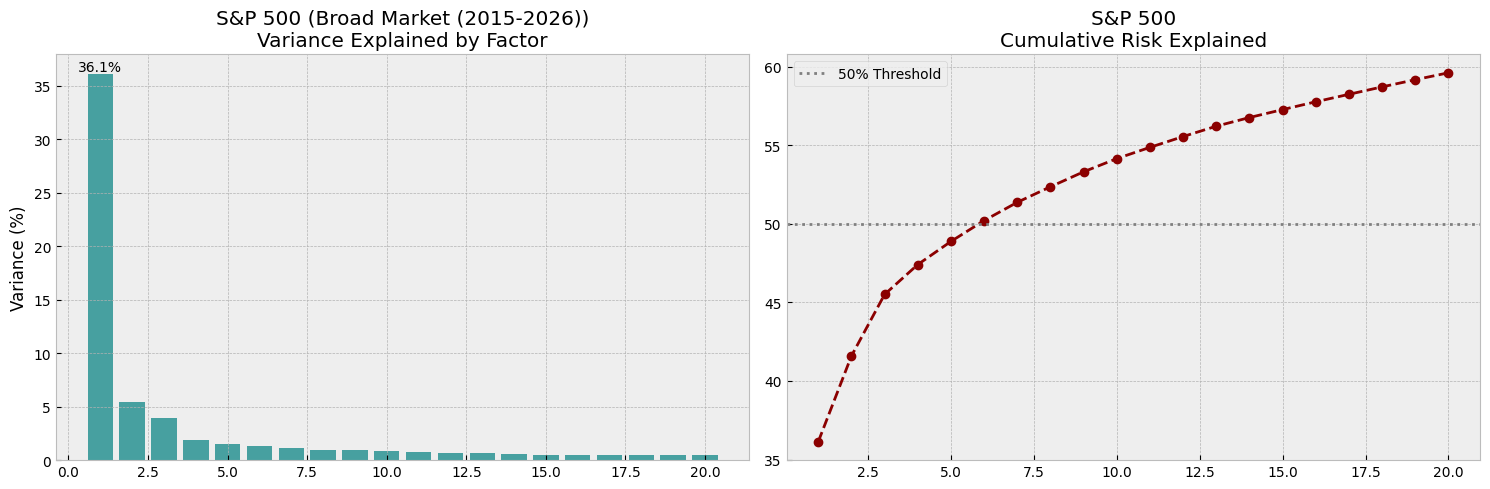

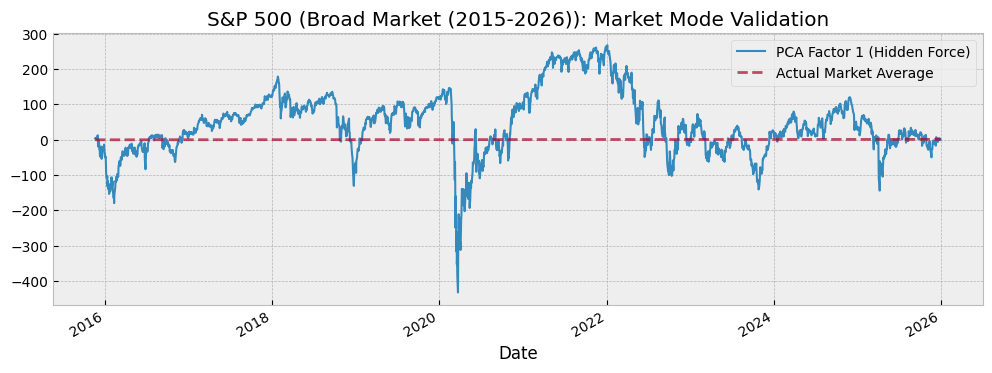

✅ Correlation between PCA and Market: 0.9980
PC1 Variance Explained: 36.14%
Cumulative Variance (20 PCs): 59.61%
--------------------------------------------------------------------------------


In [4]:
# --- MAIN EXECUTION ---
print("STARTING DUAL-COHORT ANALYSIS\n")

# 1. NIFTY ANALYSIS
run_pca_analysis("NIFTY 500", "nifty500", "long")  # 2007-2026
run_pca_analysis("NIFTY 500", "nifty500", "broad") # 2015-2026

# 2. S&P 500 ANALYSIS
run_pca_analysis("S&P 500", "sp500", "long")   # 2007-2026
run_pca_analysis("S&P 500", "sp500", "broad")  # 2015-2026

In [10]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def beta_reduction_summary(returns_df, k_factors=N_COMPONENTS):

    # -----------------------------
    # 1. MARKET PROXY (Equal Weighted)
    # -----------------------------
    clean = returns_df.dropna(axis=0)
    market_proxy = clean.mean(axis=1)

    # -----------------------------
    # 2. PRE-PCA MARKET CORRELATION
    # -----------------------------
    pre_corr = returns_df.corrwith(market_proxy)

    avg_pre_beta = pre_corr.mean()
    std_pre_beta = pre_corr.std()

    # 3. PCA FACTOR REMOVAL
    # Standardize

    
    scaler = StandardScaler()
    scaled = scaler.fit_transform(clean)
   # PCA
    pca = PCA(
        n_components=k_factors,random_state=42)
    factors = pca.fit_transform(scaled)
    reconstructed = pca.inverse_transform(factors)
    # Convert back
    reconstructed = scaler.inverse_transform(reconstructed)
    reconstructed = pd.DataFrame(
        reconstructed,
        index=clean.index,
        columns=clean.columns)
    residuals = clean - reconstructed

   

    # -----------------------------
    # 4. POST-PCA MARKET CORRELATION
    # -----------------------------
    post_corr = residuals.corrwith(market_proxy)

    avg_post_beta = post_corr.mean()
    std_post_beta = post_corr.std()

    # -----------------------------
    # 5. SUMMARY TABLE
    # -----------------------------
    summary_table = pd.DataFrame({
        "Metric": ["Average Market Correlation", "Std Dev of Correlation"],
        "Before PCA": [avg_pre_beta, std_pre_beta],
        "After PCA": [avg_post_beta, std_post_beta]
    })

    return summary_table.round(4)

In [11]:
# ==========================================
# LOAD RETURN MATRICES FOR PCA VALIDATION
# ==========================================

nifty_long_returns = pd.read_parquet(
    DATA_PROCESSED / "nifty500_returns.parquet"
)

nifty_broad_returns = pd.read_parquet(
    DATA_PROCESSED / "nifty500_2015_returns.parquet"
)

sp_long_returns = pd.read_parquet(
    DATA_PROCESSED / "sp500_returns.parquet"
)

sp_broad_returns = pd.read_parquet(
    DATA_PROCESSED / "sp500_2015_returns.parquet"
)

print("All return matrices loaded successfully.")

All return matrices loaded successfully.


In [12]:
print("\nNIFTY 500 (Long Cohort)")
display(beta_reduction_summary(nifty_long_returns))

print("\nNIFTY 500 (Broad Cohort)")
display(beta_reduction_summary(nifty_broad_returns))

print("\nS&P 500 (Long Cohort)")
display(beta_reduction_summary(sp_long_returns))

print("\nS&P 500 (Broad Cohort)")
display(beta_reduction_summary(sp_broad_returns))


NIFTY 500 (Long Cohort)


,Metric,Before PCA,After PCA
0,Average Market Correlation,0.4628,0.0001
1,Std Dev of Correlation,0.0945,0.0014



NIFTY 500 (Broad Cohort)


,Metric,Before PCA,After PCA
0,Average Market Correlation,0.4718,0.0001
1,Std Dev of Correlation,0.0958,0.0015



S&P 500 (Long Cohort)


,Metric,Before PCA,After PCA
0,Average Market Correlation,0.5973,0.0000
1,Std Dev of Correlation,0.1132,0.0008



S&P 500 (Broad Cohort)


,Metric,Before PCA,After PCA
0,Average Market Correlation,0.5882,0.0000
1,Std Dev of Correlation,0.1190,0.0009
